# Adaptive clustering of free-text testimonies

This notebook runs the `textclust` package (in `../src/textclust`) step by step. Nothing in it is specific to
`Student_Dataset.csv`: change `CSV_PATH` (and, only if the automatic detection is wrong, the overrides) and run all cells.

Raw testimonies are not printed here on purpose, because the dataset is not distributed. Representative examples are
written to `metrics.json` in the (git-ignored) run folder instead.

In [1]:
# Parameters: the only cell to edit
CSV_PATH = "Student_Dataset.csv"
TEXT_COLUMN = None    # column name or 0-based index; None = auto-detect
LABEL_COLUMN = None   # reference labels for ARI/NMI; None = auto-detect, False = none
OUTPUT_DIR = "../runs"

In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path("../src").resolve()))

import logging
import matplotlib.pyplot as plt
import pandas as pd
from textclust import Config, run
from textclust import clean, features, io, model, report

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")
cfg = Config()
cfg

Config(min_tokens=2, language=None, ngram_range=(1, 1), max_components=100, target_variance=None, k_max_cap=20, fixed_k=None, algorithms=('kmeans', 'hdbscan'), max_noise=0.3, n_terms=8, n_examples=3, projection=True, random_state=42)

## 1. Loading

`load_csv` tries the encodings `utf-8-sig`, `utf-8`, `latin-1`; detects the delimiter with `csv.Sniffer` (fallback: the
most consistent candidate among `, ; tab |`); decides whether the first row is a header; repairs ragged rows (a row
with fewer fields than the table width keeps its longest field as text); then picks the text column (longest mean
length weighted by the share of letters) and a label column only if one looks categorical (2 to sqrt(n) values, not an
identifier, not constant).

In [3]:
loaded = io.load_csv(CSV_PATH, text_column=TEXT_COLUMN, label_column=LABEL_COLUMN)
{k: v for k, v in loaded.profile.items() if k != "path"}

INFO textclust.io: loaded Student_Dataset.csv: 1011 rows, encoding=utf-8-sig, delimiter=',', header=False, text=col2, label=None


{'encoding': 'utf-8-sig',
 'delimiter': ',',
 'header': False,
 'columns': ['col0', 'col1', 'col2'],
 'rows': 1011,
 'ragged_rows_repaired': {'short': 397, 'long': 0},
 'text_column': 'col2',
 'text_column_source': 'auto',
 'label_column': None,
 'label_column_source': 'auto',
 'constant_columns': ['col1']}

In this dataset the second column (`col1`, the former `Code`) only ever contains `0x000000` (or is missing on
shifted rows), so it is reported as constant and **no label column exists**: the evaluation below is internal only
(silhouette, Calinski-Harabasz, Davies-Bouldin).

## 2. Cleaning and language

Unicode NFKC normalization, lowercasing, removal of URLs, digits and punctuation (accented letters are kept). Empty
texts, texts shorter than `min_tokens` and exact duplicates are dropped. The language is the one whose stop-word list
(scikit-learn's English list, a hand-written French list) covers the most tokens.

In [4]:
data, clean_report = clean.clean_corpus(loaded.frame, loaded.text_column, cfg.min_tokens)
clean_report

INFO textclust.clean: cleaning: kept 994/1011 (empty 0, short 0, duplicates 17), language=en


{'input_rows': 1011,
 'dropped_empty': 0,
 'dropped_too_short': 0,
 'dropped_duplicates': 17,
 'kept': 994,
 'min_tokens': 2,
 'language': 'en',
 'stop_word_share': {'en': 0.5304, 'fr': 0.0926}}

## 3. Features: TF-IDF, TruncatedSVD (LSA), L2 normalization

`min_df` and `max_df` are derived from the corpus size (`min_df` = 1 below 50 documents, 2 below 2,000, 3 below
10,000, 5 above; `max_df` = 0.95 below 100 documents, 0.8 above). SVD keeps `min(100, n_terms - 1, n_docs - 1)`
components.

In [5]:
stop = clean.stop_words_for(clean_report["language"])
feats = features.build_features(data["clean_text"], stop_words=stop, random_state=cfg.random_state)
feats.params

INFO textclust.features: features: 994 docs x 1271 terms (min_df=2, max_df=0.8), SVD 100 comps, variance 0.4149


{'min_df': 2,
 'max_df': 0.8,
 'ngram_range': [1, 1],
 'n_features': 1271,
 'svd_components': 100,
 'svd_explained_variance': 0.4149,
 'stop_words': '336 words'}

## 4. Choosing k and the algorithm

K-Means is fitted for k = 2 .. min(20, max(3, sqrt(n/2))). HDBSCAN is fitted with `min_cluster_size` = 2% of the corpus
(at least 3). The candidate with the best cosine silhouette wins, among those with at least two clusters and at most
30% of points labelled as noise (otherwise HDBSCAN can score well by discarding every hard point).

In [6]:
choice = model.select_model(feats.embedding, random_state=cfg.random_state)
pd.DataFrame(choice.candidates).T[["n_clusters", "noise_ratio", "eligible", "silhouette",
                                   "calinski_harabasz", "davies_bouldin"]]

INFO textclust.model: model selection: {'kmeans': (18, 0.12484525507497378, 0.0), 'hdbscan': (3, 0.16094333010329748, 0.7716)}


INFO textclust.model: chosen: kmeans with 18 clusters, silhouette=0.125, noise=0.0%


,n_clusters,noise_ratio,eligible,silhouette,calinski_harabasz,davies_bouldin
kmeans,18,0.0,True,0.124845,15.539824,3.476134
hdbscan,3,0.7716,False,0.160943,16.072906,2.829749


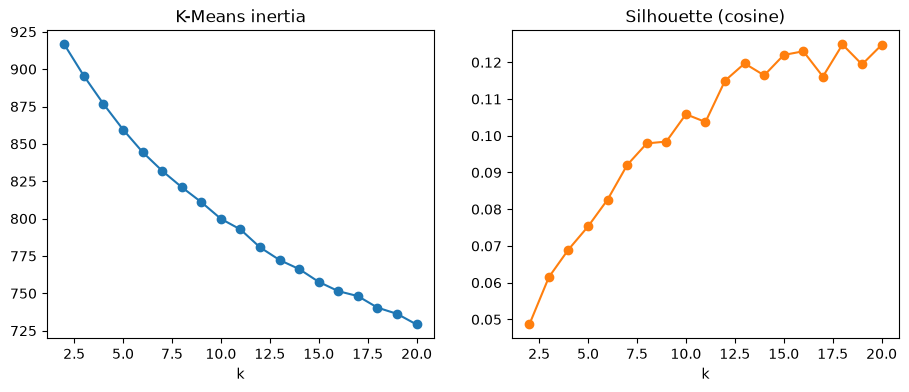

chosen: kmeans 18 clusters {'silhouette': 0.125, 'calinski_harabasz': 15.54, 'davies_bouldin': 3.476}


In [7]:
curve = pd.DataFrame(choice.k_curve)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(curve.k, curve.inertia, "o-"); ax[0].set(title="K-Means inertia", xlabel="k")
ax[1].plot(curve.k, curve.silhouette, "o-", color="tab:orange"); ax[1].set(title="Silhouette (cosine)", xlabel="k")
plt.show()
print("chosen:", choice.algorithm, choice.n_clusters, "clusters",
      {k: round(v, 3) for k, v in choice.scores.items()})

The silhouette keeps rising slowly with k, so k ends at the top of the searched range. Short free-text testimonies
form a continuum of overlapping themes rather than well-separated groups; read the value as "best among the tried
values", not as a natural number of topics.

## 5. Cluster description

In [8]:
terms = report.top_terms(feats.tfidf, choice.labels, feats.vectorizer, cfg.n_terms)
examples = report.representatives(feats.embedding, choice.labels, data[loaded.text_column], cfg.n_examples)
table = report.cluster_table(choice.labels, terms, examples)
table.drop(columns="example")

,cluster,size,top_terms
0,0,47,"hot, blister, touched, small, red, skin, hand,..."
1,1,54,"felt, nose, throat, mild, day, congestion, col..."
2,2,96,"especially, feel, vision, feeling, night, eye,..."
3,3,29,"ankle, heel, toes, sore, uneven, squeeze, walk..."
4,4,46,"breath, breathing, short, catch, cough, walkin..."
5,5,66,"itchy, rash, new, hives, raised, spots, welts,..."
6,6,51,"feel, pale, headaches, skin, looks, dizzy, hea..."
7,7,60,"ear, pain, fever, hear, cold, slight, right, h..."
8,8,57,"wrist, elbow, forearm, hand, palm, feels, fing..."
9,9,46,"shoulder, reaching, arm, overhead, makes, lift..."


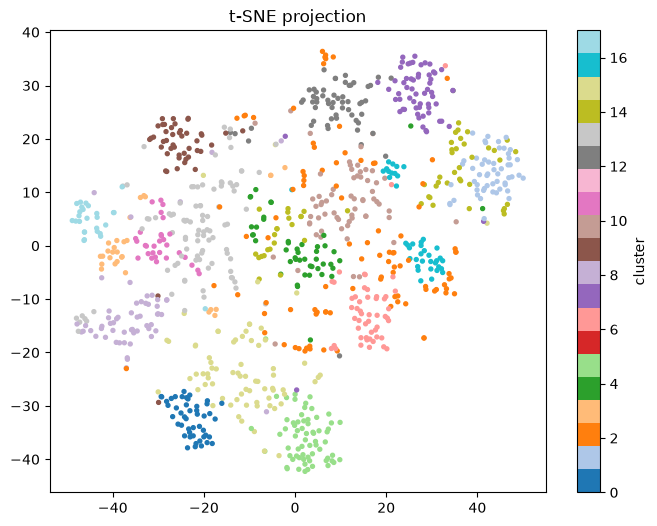

In [9]:
xy, info = report.project_2d(feats.embedding, cfg.random_state)
fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(xy[:, 0], xy[:, 1], s=8, c=choice.labels, cmap="tab20")
fig.colorbar(sc, ax=ax, label="cluster"); ax.set_title(f"{info['method']} projection")
plt.show()

## 6. Full run, saved

`run()` chains the same steps and writes `metrics.json` (data profile, cleaning report, parameters, all candidates,
k curve, sizes, top terms, examples), `assignments.csv` and the plots to a timestamped folder. The same run is
available from the command line: `python -m textclust path/to/file.csv` (with `src` on `PYTHONPATH`).

In [10]:
result = run(CSV_PATH, text_column=TEXT_COLUMN, label_column=LABEL_COLUMN, config=cfg, output_dir=OUTPUT_DIR)
print("saved to", result.run_dir.name)
result.metrics["chosen"]

INFO textclust.io: loaded Student_Dataset.csv: 1011 rows, encoding=utf-8-sig, delimiter=',', header=False, text=col2, label=None


INFO textclust.clean: cleaning: kept 994/1011 (empty 0, short 0, duplicates 17), language=en


INFO textclust.features: features: 994 docs x 1271 terms (min_df=2, max_df=0.8), SVD 100 comps, variance 0.4149


INFO textclust.model: model selection: {'kmeans': (18, 0.12484525507497378, 0.0), 'hdbscan': (3, 0.16094333010329748, 0.7716)}


INFO textclust.model: chosen: kmeans with 18 clusters, silhouette=0.125, noise=0.0%


INFO textclust.report: wrote ../runs/20261110-231011-072032/metrics.json


saved to 20261110-231011-072032


{'algorithm': 'kmeans',
 'n_clusters': 18,
 'noise_ratio': 0.0,
 'silhouette': 0.12484525507497378,
 'calinski_harabasz': 15.539823771715966,
 'davies_bouldin': 3.4761335672087,
 'k': 18,
 'k_range': [2, 20],
 'n_init': 10}